# Capstone_Oracle_Microsoft_FINAL

## Oracle (ORCL) and Microsoft (MSFT) comparative valuation capstone

**Revised after Week 7 defence | USD millions except shares, per-share values, and percentages | 6 October 2026**

This revision preserves the SEC/WRDS inputs, daily-`prccd` beta method, CAPM/WACC framework, linked FCFF mechanics, and audit gates. It updates only evidence-supported operating scenarios and the audited capital-structure treatment. Dated WRDS prices remain comparison points, not assumption inputs.


## Shared pipeline functions and file paths

The complete authoritative Oracle workpaper follows unchanged. The reusable functions later reconcile Oracle exactly before running Microsoft with its own configuration.

# Oracle: sourced extraction, audited capital structure, forecast, checks, valuation, scenarios, tornado, bridge, and honest range

This is a DCF workpaper, not a price target. Oracle's driver is OCI/AI capacity delivery and conversion of contracted demand into revenue, margin, and ultimately FCFF. The revised base follows FY2027 guidance and fades as the AI build matures; the upside assumes a durable AI infrastructure cycle. Both retain substantial reinvestment.


## AI risk and verification

AI helped with notebook structure, extraction organisation, and code. I independently verified the SEC Company Facts and Oracle FY2026 10-K figures used in the model. I specifically rejected the earlier WRDS `trfd` beta approach after verifying that it is an adjustment factor, not a daily-return series, and replaced it with beta calculated from saved WRDS Compustat Security Daily `prccd` returns.

## Oracle-specific driver

The company-specific driver is OCI/AI data-centre capacity and utilisation, unlike the ABG template; it is implemented through Oracle-specific high capex/revenue, PP&E-linked D&A, utilisation-driven margin expansion, and the possibility of early negative FCFF/additional borrowing.

In [1]:
from pathlib import Path
from copy import deepcopy
from datetime import date
import json
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'exercise4').exists(): ROOT = ROOT.parent
OUT, CACHE = ROOT / 'exercise4', ROOT / 'lab6' / 'cache'
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
assert (CACHE / 'CIK0001341439_companyfacts.json').exists(), 'SEC Company Facts cache is required.'
print('Working directory:', ROOT)
print('SEC Company Facts cache:', CACHE / 'CIK0001341439_companyfacts.json')

Working directory: /Users/douglasbuckeridge/Documents/Courses/PythonFinance2026/DouglasBuckeridge
SEC Company Facts cache: /Users/douglasbuckeridge/Documents/Courses/PythonFinance2026/DouglasBuckeridge/lab6/cache/CIK0001341439_companyfacts.json


## 1. SEC Company Facts extraction and provenance

The code below is the visible extraction rather than a hard-coded FY2024–FY2026 history. `InventoryNet` is not available for FY2026 in this Company Facts cache; its FY2026 value is therefore a clearly marked filing-only input from Oracle’s FY2026 consolidated balance sheet. Debt is total short- and long-term debt. Other operating assets are the balancing operating-asset category derived from total assets after the named assets, consistent with this simplified operating balance sheet.

In [2]:
facts = json.load(open(CACHE / 'CIK0001341439_companyfacts.json'))['facts']['us-gaap']
FYS = {2024: ('2023-06-01','2024-05-31'), 2025: ('2024-06-01','2025-05-31'), 2026: ('2025-06-01','2026-05-31')}
def sec_fact(tag, fy, duration=False):
    unit = facts[tag]['units']['USD']
    start, end = FYS[fy]
    rows = [r for r in unit if r.get('form') == '10-K' and r.get('end') == end and (not duration or r.get('start') == start)]
    if not rows: raise KeyError(f'Missing SEC fact: {tag}, FY{fy}, duration={duration}')
    return rows[-1]

tags = {
    'revenue': ('RevenueFromContractWithCustomerExcludingAssessedTax', True),
    'operating_income': ('OperatingIncomeLoss', True),
    'net_income': ('NetIncomeLoss', True),
    'capex': ('PaymentsToAcquirePropertyPlantAndEquipment', True),
    'cash': ('CashAndCashEquivalentsAtCarryingValue', False),
    'ar': ('AccountsReceivableNetCurrent', False),
    'ap': ('AccountsPayableCurrent', False),
    'ppe': ('PropertyPlantAndEquipmentNet', False),
    'assets': ('LiabilitiesAndStockholdersEquity', False),
    'equity': ('StockholdersEquity', False),
    'debt': ('DebtLongtermAndShorttermCombinedAmount', False),
}
rows, provenance = [], []
for fy in FYS:
    item = {'fy': fy}
    for label, (tag, duration) in tags.items():
        r = sec_fact(tag, fy, duration)
        item[label] = r['val'] / 1e6
        provenance.append([fy, label, tag, item[label], r['accn'], r['filed'], r.get('start', 'instant'), r['end'], 'SEC Company Facts'])
    rows.append(item)
history = pd.DataFrame(rows).set_index('fy')
# Filing-only input: Oracle FY2026 Form 10-K, Consolidated Balance Sheets, 31 May 2026, USD millions, extracted 2026-10-01.
history.loc[2026, 'inventory'] = 303.0
history['inventory'] = history['inventory'].fillna(history['inventory'].iloc[0] if 'inventory' in history else np.nan)
# Correct 2024/2025 inventory from Company Facts; FY2026 is filing-only as documented above.
history.loc[2024, 'inventory'] = sec_fact('InventoryNet', 2024)['val'] / 1e6
history.loc[2025, 'inventory'] = sec_fact('InventoryNet', 2025)['val'] / 1e6
history['liabilities'] = history['assets'] - history['equity']
# Net other operating assets: filing other assets less filing other liabilities. This keeps the
# simplified forecast balance sheet to the required named asset/liability lines without plugging cash or equity.
history['other_operating_assets'] = (history['assets'] - history['cash'] - history['ar'] - history['inventory'] - history['ppe']) - (history['liabilities'] - history['ap'] - history['debt'])
history['revenue_growth'] = history['revenue'].pct_change()
history['operating_margin'] = history['operating_income'] / history['revenue']
history['capex_revenue'] = history['capex'] / history['revenue']
provenance.append([2026, 'inventory', 'Filing-only: Consolidated Balance Sheets', 303.0, '0001193125-26-277521', '2026-06-22', 'instant', '2026-05-31', 'Oracle FY2026 10-K; USD m; extracted 2026-10-01'])
prov = pd.DataFrame(provenance, columns=['FY','Item','SEC tag / statement','USD m','Accession','Filed','Start','End','Provenance'])
display(history)
display(prov.sort_values(['FY','Item']))

,revenue,operating_income,net_income,capex,cash,ar,ap,ppe,assets,equity,debt,inventory,liabilities,other_operating_assets,revenue_growth,operating_margin,capex_revenue
fy,,,,,,,,,,,,,,,,,
2024,"52,961.00","15,353.00","10,467.00","6,866.00","10,454.00","7,874.00","2,357.00","21,536.00","140,976.00","8,704.00","86,869.00",334.00,"132,272.00","57,732.00",NaN,0.29,0.13
2025,"57,399.00","17,678.00","12,443.00","21,215.00","10,786.00","8,558.00","5,113.00","43,522.00","168,361.00","20,451.00","92,568.00",303.00,"147,910.00","54,963.00",0.08,0.31,0.37
2026,"67,357.00","20,606.00","17,087.00","55,663.00","31,289.00","10,385.00","10,977.00","99,957.00","261,759.00","42,508.00","129,541.00",303.00,"219,251.00","41,092.00",0.17,0.31,0.83


,FY,Item,SEC tag / statement,USD m,Accession,Filed,Start,End,Provenance
6,2024,ap,AccountsPayableCurrent,"2,357.00",0000950170-25-087926,2025-06-18,instant,2024-05-31,SEC Company Facts
5,2024,ar,AccountsReceivableNetCurrent,"7,874.00",0000950170-25-087926,2025-06-18,instant,2024-05-31,SEC Company Facts
8,2024,assets,LiabilitiesAndStockholdersEquity,"140,976.00",0000950170-25-087926,2025-06-18,instant,2024-05-31,SEC Company Facts
3,2024,capex,PaymentsToAcquirePropertyPlantAndEquipment,"6,866.00",0001193125-26-277521,2026-06-22,2023-06-01,2024-05-31,SEC Company Facts
4,2024,cash,CashAndCashEquivalentsAtCarryingValue,"10,454.00",0000950170-25-087926,2025-06-18,instant,2024-05-31,SEC Company Facts
10,2024,debt,DebtLongtermAndShorttermCombinedAmount,"86,869.00",0000950170-25-087926,2025-06-18,instant,2024-05-31,SEC Company Facts
9,2024,equity,StockholdersEquity,"8,704.00",0000950170-25-087926,2025-06-18,instant,2024-05-31,SEC Company Facts
2,2024,net_income,NetIncomeLoss,"10,467.00",0001193125-26-277521,2026-06-22,2023-06-01,2024-05-31,SEC Company Facts
1,2024,operating_income,OperatingIncomeLoss,"15,353.00",0001193125-26-277521,2026-06-22,2023-06-01,2024-05-31,SEC Company Facts
7,2024,ppe,PropertyPlantAndEquipmentNet,"21,536.00",0000950170-25-087926,2025-06-18,instant,2024-05-31,SEC Company Facts


## 2. FY2026 known-answer gate and filing-only opening items

The SEC-derived income-statement values must match the FY2026 filed results before forecasting. Latest shares are filing-only: Oracle Form 10-Q cover, 7 September 2026, 3,023.736 million shares, filed 11 September 2026. The debt balance is retained at the SEC Company Facts total-debt amount.

In [3]:
opening = history.loc[2026, ['revenue','cash','ar','inventory','ap','ppe','assets','liabilities','equity','debt','other_operating_assets']].to_dict()
opening['shares'] = 3023.736  # Filing-only: 2026 Q1 10-Q cover, 2026-09-07, shares m, extracted 2026-10-01.
opening['net_debt'] = opening['debt'] - opening['cash']
filed = pd.Series({'Revenue': 67357.0, 'Operating income': 20606.0, 'Net income': 17087.0, 'Shares (m)': 3023.736, 'Net debt': 98252.0})
rebuilt = pd.Series({'Revenue': history.loc[2026,'revenue'], 'Operating income': history.loc[2026,'operating_income'], 'Net income': history.loc[2026,'net_income'], 'Shares (m)': opening['shares'], 'Net debt': opening['net_debt']})
gate = pd.DataFrame({'Filed FY2026': filed, 'Rebuilt': rebuilt})
gate['Difference'] = gate['Rebuilt'] - gate['Filed FY2026']; gate['Pass'] = gate['Difference'].abs() < 0.01
display(gate)
assert gate['Pass'].all(), 'KNOWN-ANSWER GATE FAILED'
print('KNOWN-ANSWER GATE: PASS')

,Filed FY2026,Rebuilt,Difference,Pass
Revenue,"67,357.00","67,357.00",0.00,True
Operating income,"20,606.00","20,606.00",0.00,True
Net income,"17,087.00","17,087.00",0.00,True
Shares (m),"3,023.74","3,023.74",0.00,True
Net debt,"98,252.00","98,252.00",0.00,True


KNOWN-ANSWER GATE: PASS


## 3. WRDS Compustat Security Daily beta — required valuation gate

This notebook uses only the locally saved WRDS audit and daily closing-price return series. It recalculates beta as `cov(ORCL return, SPY return) / var(SPY return)` from Compustat Security Daily `prccd`, with daily return equal to `prccd / lag(prccd) - 1`. There is no typed beta and no alternate market-data path. If the audit or return series is unavailable, malformed, not explicitly a successful `prccd` pull, or fails the observation/range gate, the notebook raises an error and no valuation is produced.

The saved series is a 24-month pull ending 30 September 2026. The earlier `trfd` method was rejected after verification because `trfd` is an adjustment factor, not a daily-return series.

In [4]:
audit_path = OUT / 'wrds_beta_audit.csv'
returns_path = OUT / 'wrds_compustat_orcl_spy_daily_returns.csv'
if not audit_path.exists() or not returns_path.exists():
    raise RuntimeError('VALUATION REFUSED: required WRDS prccd audit or return-series file is missing.')
beta_audit = pd.read_csv(audit_path)
returns = pd.read_csv(returns_path, parse_dates=['datadate'])
required = {'datadate','ORCL','SPY'}
if not required.issubset(returns.columns):
    raise RuntimeError('VALUATION REFUSED: WRDS return series lacks required ORCL/SPY columns.')
if not ((beta_audit['status'].eq('success')).any() and beta_audit['source'].str.contains('prccd', case=False, na=False).any()):
    raise RuntimeError('VALUATION REFUSED: no successful WRDS Compustat Security Daily prccd audit.')
returns = returns[['datadate','ORCL','SPY']].dropna().sort_values('datadate')
if len(returns) < 100:
    raise RuntimeError(f'VALUATION REFUSED: only {len(returns)} matched WRDS daily returns; 100 required.')
WRDS_BETA = float(returns['ORCL'].cov(returns['SPY']) / returns['SPY'].var())
if not 0.20 <= WRDS_BETA <= 3.00:
    raise RuntimeError(f'VALUATION REFUSED: WRDS prccd beta {WRDS_BETA:.4f} failed 0.20–3.00 gate.')
audit_out = pd.DataFrame([{'run_date': date.today().isoformat(), 'source': 'WRDS Compustat Security Daily: ORCL and SPY prccd', 'status': 'success', 'detail': f'{len(returns)} matched daily return observations; beta={WRDS_BETA:.4f}; recalculated from saved WRDS prccd return series.'}])
audit_out.to_csv(audit_path, index=False)
returns.to_csv(returns_path, index=False)
display(audit_out); display(returns.head()); display(returns.tail())
print(f'FINAL WRDS BETA = {WRDS_BETA:.4f}; observations={len(returns)}; {returns.datadate.min().date()} to {returns.datadate.max().date()}')

,run_date,source,status,detail
0,2026-10-06,WRDS Compustat Security Daily: ORCL and SPY prccd,success,501 matched daily return observations; beta=1....


,datadate,ORCL,SPY
0,2024-10-01,-0.02,-0.01
1,2024-10-02,0.00,0.00
2,2024-10-03,-0.01,-0.00
3,2024-10-04,0.02,0.01
4,2024-10-07,-0.01,-0.01


,datadate,ORCL,SPY
496,2026-09-24,-0.03,-0.00
497,2026-09-25,-0.02,0.01
498,2026-09-28,-0.03,-0.01
499,2026-09-29,0.04,-0.00
500,2026-09-30,-0.00,-0.00


FINAL WRDS BETA = 1.6369; observations=501; 2024-10-01 to 2026-09-30


## 4. Revised Oracle operating assumptions

Evidence anchor: FY2026 revenue was $67.4bn (+17%); Q1 FY2027 revenue was +30%, cloud +62%, OCI +121%, and management guided FY2027 total revenue to at least $90bn and Q2 cloud revenue to +65%–71%. The base starts at 35% total revenue growth—near the full-year guide—and fades to 8%. The upside assumes demand and capacity conversion remain unusually strong through FY2031.

Capex is deliberately high: Oracle reported FY2026 capex of $55.7bn and Q1 FY2027 capex of $28.5bn, with FY2027 capex expected to exceed FY2026. Customer prepayments/supplied GPUs can improve later efficiency but do not make the build free. Revenue growth, operating-profit conversion, and FCFF conversion are modeled separately.


In [5]:
MANUAL = dict(risk_free_rate=.0506, equity_risk_premium=.04234, terminal_growth=.0300,
              cash_floor=10000.0, dividend_pct_ni=.32, price=137.79,
              price_date='2026-09-29', price_source='WRDS Compustat Security Daily',
              valuation_debt=125337.0, valuation_net_debt=88968.0,
              valuation_balance_date='2026-08-31')
# FY2027–FY2031. Base = guidance-led fade; upside = durable AI infrastructure boom.
BASE = dict(growth=[.35,.28,.20,.14,.08], margin=[.35,.37,.39,.40,.41], tax=[.22]*5,
            capex=[.70,.55,.42,.32,.25], da_ppe=[.15,.16,.17,.18,.18],
            ar=opening['ar']/opening['revenue'], inventory=opening['inventory']/opening['revenue'],
            ap=opening['ap']/opening['revenue'], ono=opening['other_operating_assets']/opening['revenue'],
            debt_rate=.045, beta=WRDS_BETA)
assumption_table = pd.DataFrame({'Revenue growth':BASE['growth'],'EBIT margin':BASE['margin'],
                                 'Capex / revenue':BASE['capex'],'D&A / opening PP&E':BASE['da_ppe']}, index=range(2027,2032))
display(assumption_table.style.format('{:.1%}'))
oracle_change_log=pd.DataFrame([
 ['Base revenue growth','20%, 18%, 16%, 10%, 7%','35%, 28%, 20%, 14%, 8%','FY2027 guide is at least $90bn from $67.4bn FY2026; Q1 revenue +30% and OCI +121%. The fade remains material.','Oracle Q1 FY2027 earnings release / Form 10-Q'],
 ['Base EBIT margin','31.5% → 35.0%','35.0% → 41.0%','OCI mix and scale can improve operating leverage, but margin expands gradually after the capex-led build.','Oracle Q1 FY2027 GAAP operating margin and results'],
 ['Base capex/revenue','70%, 55%, 42%, 32%, 25%','Unchanged','Keeps the infrastructure build intact; this is not a valuation-driven reinvestment reduction.','Oracle FY2026 10-K; Q1 FY2027 capex $28.5bn'],
 ['Terminal growth / WACC','3.0% / same method','Unchanged / same method','Long-run mechanics are retained; no market-price calibration.','Existing audited CAPM/WACC framework']
],columns=['Assumption','Old','Proposed','Economic rationale','Primary evidence'])
display(oracle_change_log)


,Revenue growth,EBIT margin,Capex / revenue,D&A / opening PP&E
2027,35.0%,35.0%,70.0%,15.0%
2028,28.0%,37.0%,55.0%,16.0%
2029,20.0%,39.0%,42.0%,17.0%
2030,14.0%,40.0%,32.0%,18.0%
2031,8.0%,41.0%,25.0%,18.0%


,Assumption,Old,Proposed,Economic rationale,Primary evidence
0,Base revenue growth,"20%, 18%, 16%, 10%, 7%","35%, 28%, 20%, 14%, 8%",FY2027 guide is at least $90bn from $67.4bn FY...,Oracle Q1 FY2027 earnings release / Form 10-Q
1,Base EBIT margin,31.5% → 35.0%,35.0% → 41.0%,OCI mix and scale can improve operating levera...,Oracle Q1 FY2027 GAAP operating margin and res...
2,Base capex/revenue,"70%, 55%, 42%, 32%, 25%",Unchanged,Keeps the infrastructure build intact; this is...,Oracle FY2026 10-K; Q1 FY2027 capex $28.5bn
3,Terminal growth / WACC,3.0% / same method,Unchanged / same method,Long-run mechanics are retained; no market-pri...,Existing audited CAPM/WACC framework


## 5. Linked forecast: income statement → balance sheet → cash flow → FCFF

Cash is calculated last from the cash-flow statement. Equity is a calculated roll-forward: opening equity plus net income less dividends. The borrowing line is also calculated—only the amount required to keep cash at the stated floor is borrowed. Total assets are exactly cash + accounts receivable + inventory + other operating assets + PP&E; total liabilities are exactly accounts payable + debt.

In [6]:
company = dict(revenue=opening['revenue'], cash=opening['cash'], ar=opening['ar'], inventory=opening['inventory'],
               ap=opening['ap'], ono=opening['other_operating_assets'], ppe=opening['ppe'], debt=opening['debt'], equity=opening['equity'])
def project(c, d, m):
    q, rows = deepcopy(c), []
    for i, year in enumerate(range(2027, 2032)):
        revenue = q['revenue'] * (1 + d['growth'][i]); ebit = revenue * d['margin'][i]
        interest = q['debt'] * d['debt_rate']; pretax = ebit - interest; taxes = max(pretax, 0) * d['tax'][i]
        net_income = pretax - taxes; nopat = ebit * (1 - d['tax'][i])
        capex = revenue * d['capex'][i]; da = q['ppe'] * d['da_ppe'][i]; ppe = q['ppe'] + capex - da
        ar, inventory, ap, ono = (revenue*d['ar'], revenue*d['inventory'], revenue*d['ap'], revenue*d['ono'])
        prior_nwc = q['ar'] + q['inventory'] + q['ono'] - q['ap']; nwc = ar + inventory + ono - ap; delta_nwc = nwc - prior_nwc
        dividends = net_income * m['dividend_pct_ni']; cash_before_debt = q['cash'] + net_income + da - delta_nwc - capex - dividends
        incremental_borrowing = max(m['cash_floor'] - cash_before_debt, 0.0)
        debt = q['debt'] + incremental_borrowing
        cash = cash_before_debt + incremental_borrowing  # calculated last; never a plug
        equity = q['equity'] + net_income - dividends    # calculated roll-forward
        assets = cash + ar + inventory + ono + ppe
        liabilities = ap + debt
        fcff = nopat + da - capex - delta_nwc
        rows.append(dict(year=year,revenue=revenue,ebit=ebit,interest=interest,pretax_income=pretax,taxes=taxes,nopat=nopat,net_income=net_income,
                         ar=ar,inventory=inventory,other_operating_assets=ono,ppe=ppe,cash=cash,assets=assets,ap=ap,debt=debt,liabilities=liabilities,equity=equity,
                         capex=capex,da=da,delta_nwc=delta_nwc,fcff=fcff,dividends=dividends,incremental_borrowing=incremental_borrowing))
        q = dict(revenue=revenue,cash=cash,ar=ar,inventory=inventory,ap=ap,ono=ono,ppe=ppe,debt=debt,equity=equity)
    return pd.DataFrame(rows).set_index('year')
def checks(p, m):
    prior_cash = p['cash'].shift(1).fillna(opening['cash'])
    out = pd.DataFrame(index=p.index)
    out['Balance identity: assets − liabilities − equity'] = p['assets'] - p['liabilities'] - p['equity']
    out['Cash-flow tie'] = p['cash'] - (prior_cash + p['net_income'] + p['da'] - p['delta_nwc'] - p['capex'] - p['dividends'] + p['incremental_borrowing'])
    out['Cash-floor check: cash − floor'] = p['cash'] - m['cash_floor']
    out['PASS'] = (out.iloc[:,0].abs() < .01) & (out.iloc[:,1].abs() < .01) & (out.iloc[:,2] >= -.01)
    return out
projection = project(company, BASE, MANUAL); forecast_checks = checks(projection, MANUAL)
display(projection[['revenue','ebit','net_income','capex','da','fcff','incremental_borrowing','cash','debt']])
display(forecast_checks)
assert forecast_checks['PASS'].all(), 'FORECAST CHECK FAILED'
print('ALL FORECAST BALANCE, CASH-FLOW TIE, AND CASH-FLOOR CHECKS: PASS')

,revenue,ebit,net_income,capex,da,fcff,incremental_borrowing,cash,debt
year,,,,,,,,,
2027,"90,931.95","31,826.18","20,277.53","63,652.37","14,993.55","-38,115.44","27,862.14","10,000.00","157,403.14"
2028,"116,392.90","43,065.37","28,066.14","64,016.09","23,778.53","-22,070.11","36,576.12","10,000.00","193,979.26"
2029,"139,671.48","54,471.88","35,679.39","58,662.02","32,105.07","1,829.60","16,396.48","10,000.00","210,375.74"
2030,"159,225.48","63,690.19","42,294.16","50,952.15","38,773.86","25,654.78",0.00,"14,736.46","210,375.74"
2031,"171,963.52","70,505.04","47,609.75","42,990.88","40,965.95","45,252.66",0.00,"37,369.81","210,375.74"


,Balance identity: assets − liabilities − equity,Cash-flow tie,Cash-floor check: cash − floor,PASS
year,,,,
2027,-0.00,0.00,0.00,True
2028,-0.00,0.00,0.00,True
2029,-0.00,0.00,0.00,True
2030,-0.00,0.00,"4,736.46",True
2031,-0.00,0.00,"27,369.81",True


ALL FORECAST BALANCE, CASH-FLOW TIE, AND CASH-FLOOR CHECKS: PASS


## 6. WACC, valuation gate, scenarios, and terminal value

The final WRDS beta is used directly in cost of equity, WACC, scenarios, tornado analysis, bridge, and all supporting files. Because this is an FCFF valuation, WACC uses market-value equity and filed financing debt. Oracle's valuation bridge uses its latest available Q1 FY2027 cash/debt position (31 August 2026), while its dated WRDS price is 29 September 2026. Terminal growth must remain below WACC.


In [7]:
def value(c, d, m):
    p = project(c, d, m); ck = checks(p, m)
    if not ck['PASS'].all(): raise ValueError('VALUATION REFUSED: forecast checks failed.')
    beta = d.get('beta')
    if beta is None or abs(beta - WRDS_BETA) > 1e-12: raise ValueError('VALUATION REFUSED: final WRDS beta is required consistently.')
    cost_of_equity = m['risk_free_rate'] + beta * m['equity_risk_premium']
    debt_value = m.get('valuation_debt', opening['debt'])
    market_equity = m['price'] * opening['shares']
    we = market_equity/(market_equity + debt_value); wd = 1 - we
    wacc = we*cost_of_equity + wd*d['debt_rate']*(1-d['tax'][0])
    if m['terminal_growth'] >= wacc: raise ValueError('VALUATION REFUSED: terminal growth must be below WACC.')
    t = np.arange(1,6); pv_fcff = (p['fcff'].values/(1+wacc)**t).sum()
    pv_tv = p['fcff'].iloc[-1]*(1+m['terminal_growth'])/(wacc-m['terminal_growth'])/(1+wacc)**5
    ev = pv_fcff + pv_tv; equity_value = ev - m.get('valuation_net_debt', opening['net_debt'])
    return dict(projection=p,cost_of_equity=cost_of_equity,we=we,wd=wd,wacc=wacc,pv_fcff=pv_fcff,pv_tv=pv_tv,ev=ev,equity_value=equity_value,
                per_share=equity_value/opening['shares'],tv_share=pv_tv/ev,implied_ev_ebit=ev/p['ebit'].iloc[0])
v = value(company, BASE, MANUAL)
display(pd.DataFrame([v]).drop(columns='projection').T.rename(columns={0:'Base case'}))
SCENARIOS = {'Downside': {'growth':[.28,.20,.14,.10,.07], 'margin':[.30,.31,.32,.33,.34], 'capex':[.78,.65,.52,.40,.30]},
             'Base': {},
             'Upside': {'growth':[.45,.38,.32,.27,.20], 'margin':[.36,.40,.43,.45,.465], 'capex':[.70,.55,.40,.25,.18]}}
scenario_rows=[]
for name, change in SCENARIOS.items():
    d=deepcopy(BASE); d.update(change); r=value(company,d,MANUAL)
    scenario_rows.append([name,r['per_share'],r['tv_share'],r['wacc']])
scenarios = pd.DataFrame(scenario_rows,columns=['Scenario','Value / share','Terminal value / EV','WACC'])
display(scenarios.style.format({'Value / share':'${:,.2f}','Terminal value / EV':'{:.1%}','WACC':'{:.2%}'}))
print('The range is independent of market price. High capex and early negative FCFF are retained; the upside depends on later operating leverage and capital efficiency.')


,Base case
cost_of_equity,0.12
we,0.77
wd,0.23
wacc,0.10
pv_fcff,"-5,933.10"
pv_tv,"411,161.37"
ev,"405,228.27"
equity_value,"316,260.27"
per_share,104.59
tv_share,1.01


,Scenario,Value / share,Terminal value / EV,WACC
0,Downside,$53.78,115.4%,10.03%
1,Base,$104.59,101.5%,10.03%
2,Upside,$173.89,100.0%,10.03%


The range is independent of market price. High capex and early negative FCFF are retained; the upside depends on later operating leverage and capital efficiency.


## 7. Operational-driver tornado

The tornado contains only operational/value drivers: revenue growth, operating margin, capex/revenue, and terminal growth. It is sorted by value swing. The business explanation below is tied specifically to the largest business-driver bar, not to a financing-market assumption.

In [8]:
SENSITIVITIES = {'FY2027 revenue growth':('growth',0,.08,.30), 'FY2031 operating margin':('margin',4,.31,.43),
                 'FY2027 capex / revenue':('capex',0,.85,.68), 'Terminal growth':('terminal_growth',None,.020,.030)}
tornado_rows=[]
for name,(field,index,low,high) in SENSITIVITIES.items():
    vals=[]
    for x in (low,high):
        d,m=deepcopy(BASE),deepcopy(MANUAL)
        if index is None: m[field]=x
        else: d[field][index]=x
        vals.append(value(company,d,m)['per_share'])
    tornado_rows.append([name,*vals,abs(vals[1]-vals[0])])
tornado=pd.DataFrame(tornado_rows,columns=['Driver','Low value / share','High value / share','Swing']).sort_values('Swing',ascending=False)
display(tornado.style.format({'Low value / share':'${:,.2f}','High value / share':'${:,.2f}','Swing':'${:,.2f}'}))
business_tornado=tornado[tornado['Driver']!='Terminal growth'].iloc[0]['Driver']
print(f'Largest business-driver bar: {business_tornado}.')
print('Its low case requires OCI/AI capacity utilisation and booked demand to fall short enough that Oracle cannot earn adequate returns on the new data-centre footprint.')
print('Its high case requires sustained OCI/AI demand and utilisation high enough for operating leverage to overcome the cost and depreciation burden while capacity converts into cash flow.')

,Driver,Low value / share,High value / share,Swing
1,FY2031 operating margin,$61.54,$113.20,$51.67
3,Terminal growth,$86.50,$104.59,$18.09
0,FY2027 revenue growth,$88.58,$101.63,$13.04
2,FY2027 capex / revenue,$106.46,$104.34,$2.12


Largest business-driver bar: FY2031 operating margin.
Its low case requires OCI/AI capacity utilisation and booked demand to fall short enough that Oracle cannot earn adequate returns on the new data-centre footprint.
Its high case requires sustained OCI/AI demand and utilisation high enough for operating leverage to overcome the cost and depreciation burden while capacity converts into cash flow.


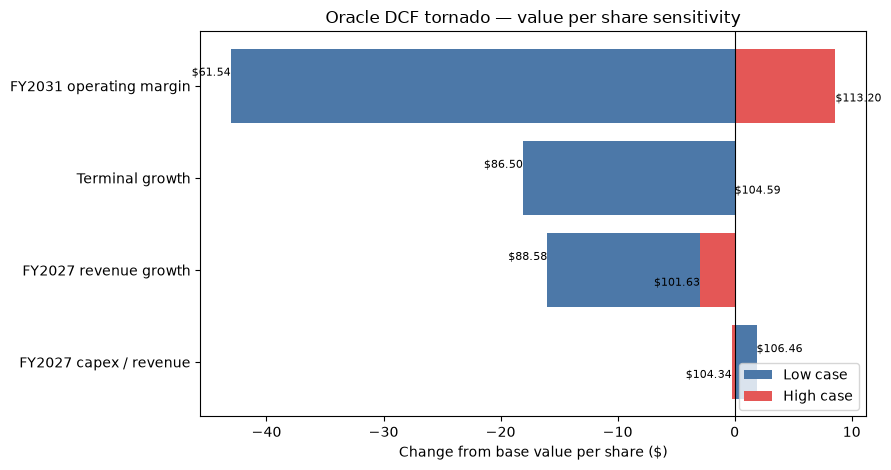

In [9]:
# Chart uses the existing calculated tornado results only; it does not alter ranges or inputs.
import matplotlib.pyplot as plt

chart = tornado.sort_values('Swing', ascending=True).copy()
base_value = v['per_share']
low_delta = chart['Low value / share'] - base_value
high_delta = chart['High value / share'] - base_value
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(chart['Driver'], low_delta, color='#4C78A8', label='Low case')
ax.barh(chart['Driver'], high_delta, color='#E45756', label='High case')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Oracle DCF tornado — value per share sensitivity')
ax.set_xlabel('Change from base value per share ($)')
ax.legend(loc='lower right')
for y, (low, high) in enumerate(zip(chart['Low value / share'], chart['High value / share'])):
    ax.text(low - base_value, y + 0.14, f'${low:,.2f}', ha='right' if low < base_value else 'left', va='center', fontsize=8)
    ax.text(high - base_value, y - 0.14, f'${high:,.2f}', ha='right' if high < base_value else 'left', va='center', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

## 8. Bridge, comparison with the dated WRDS price, and final judgment

The dated market comparison uses the $137.79 WRDS Compustat Security Daily price on 29 September 2026. The bridge reports all stale-output replacement measures: WACC, terminal-value share, implied EV/FY2027 EBIT, enterprise value, equity value, and value per share.

In [10]:
bridge = pd.DataFrame({'Measure':['Final WRDS beta','Cost of equity','WACC','PV of explicit FCFF','PV of terminal value','Terminal value / EV','Enterprise value','Less: net debt','Equity value','Shares (m)','Value / share','Dated WRDS price','Difference vs price','Implied EV / FY2027 EBIT'],
                       'Value':[WRDS_BETA,v['cost_of_equity'],v['wacc'],v['pv_fcff'],v['pv_tv'],v['tv_share'],v['ev'],-opening['net_debt'],v['equity_value'],opening['shares'],v['per_share'],MANUAL['price'],v['per_share']/MANUAL['price']-1,v['implied_ev_ebit']]})
display(bridge)
print('My base case assumes strong OCI growth but slower cash-flow conversion and margin realisation than the market appears to expect. The market price implies a faster or more profitable payback from Oracle’s data-centre investment than my base case supports.')

,Measure,Value
0,Final WRDS beta,1.64
1,Cost of equity,0.12
2,WACC,0.10
3,PV of explicit FCFF,"-5,933.10"
4,PV of terminal value,"411,161.37"
5,Terminal value / EV,1.01
6,Enterprise value,"405,228.27"
7,Less: net debt,"-98,252.00"
8,Equity value,"316,260.27"
9,Shares (m),"3,023.74"


My base case assumes strong OCI growth but slower cash-flow conversion and margin realisation than the market appears to expect. The market price implies a faster or more profitable payback from Oracle’s data-centre investment than my base case supports.


## 9. Full pro-forma exhibit and impossible-input check

This exhibit is generated from the same base-case forecast used above. The check table repeats for every forecast year immediately below the balance sheet and cash-flow schedules.

In [11]:
p=projection
income = pd.DataFrame({'Revenue':p.revenue,'EBIT':p.ebit,'Interest':p.interest,'Pretax income':p.pretax_income,'Taxes':p.taxes,'Net income':p.net_income}).T
balance = pd.DataFrame({'Cash (calculated last)':p.cash,'Accounts receivable':p.ar,'Inventory':p.inventory,'Other operating assets':p.other_operating_assets,'PP&E':p.ppe,'Total assets':p.assets,'Accounts payable':p.ap,'Debt':p.debt,'Total liabilities':p.liabilities,'Equity (roll-forward)':p.equity}).T
cashflow = pd.DataFrame({'Net income':p.net_income,'D&A':p.da,'Less: change in NWC':-p.delta_nwc,'Less: capex':-p.capex,'Less: dividends':-p.dividends,'Incremental borrowing':p.incremental_borrowing,'Ending cash':p.cash,'FCFF':p.fcff}).T
display(income.style.format('{:,.1f}')); display(balance.style.format('{:,.1f}')); display(cashflow.style.format('{:,.1f}')); display(forecast_checks.style.format('{:,.2f}'))
try:
    bad=deepcopy(MANUAL); bad['terminal_growth']=v['wacc']; value(company,BASE,bad)
except ValueError as exc: print('EXPECTED IMPOSSIBLE-INPUT FAILURE:', exc)

year,2027,2028,2029,2030,2031
Revenue,"90,932.0","116,392.9","139,671.5","159,225.5","171,963.5"
EBIT,"31,826.2","43,065.4","54,471.9","63,690.2","70,505.0"
Interest,"5,829.3","7,083.1","8,729.1","9,466.9","9,466.9"
Pretax income,"25,996.8","35,982.2","45,742.8","54,223.3","61,038.1"
Taxes,"5,719.3","7,916.1","10,063.4","11,929.1","13,428.4"
Net income,"20,277.5","28,066.1","35,679.4","42,294.2","47,609.7"


year,2027,2028,2029,2030,2031
Cash (calculated last),"10,000.0","10,000.0","10,000.0","14,736.5","37,369.8"
Accounts receivable,"14,019.8","17,945.3","21,534.3","24,549.1","26,513.1"
Inventory,409.1,523.6,628.3,716.3,773.6
Other operating assets,"55,474.2","71,007.0","85,208.4","97,137.5","104,908.5"
PP&E,"148,615.8","188,853.4","215,410.3","227,588.6","229,613.5"
Total assets,"228,518.8","288,329.2","332,781.3","364,728.0","399,178.5"
Accounts payable,"14,819.0","18,968.3","22,761.9","25,948.6","28,024.5"
Debt,"157,403.1","193,979.3","210,375.7","210,375.7","210,375.7"
Total liabilities,"172,222.1","212,947.5","233,137.6","236,324.3","238,400.2"
Equity (roll-forward),"56,296.7","75,381.7","99,643.7","128,403.7","160,778.3"


year,2027,2028,2029,2030,2031
Net income,"20,277.5","28,066.1","35,679.4","42,294.2","47,609.7"
D&A,"14,993.5","23,778.5","32,105.1","38,773.9","40,966.0"
Less: change in NWC,"-14,281.1","-15,423.5","-14,101.5","-11,845.3","-7,716.3"
Less: capex,"-63,652.4","-64,016.1","-58,662.0","-50,952.2","-42,990.9"
Less: dividends,"-6,488.8","-8,981.2","-11,417.4","-13,534.1","-15,235.1"
Incremental borrowing,"27,862.1","36,576.1","16,396.5",0.0,0.0
Ending cash,"10,000.0","10,000.0","10,000.0","14,736.5","37,369.8"
FCFF,"-38,115.4","-22,070.1","1,829.6","25,654.8","45,252.7"


,Balance identity: assets − liabilities − equity,Cash-flow tie,Cash-floor check: cash − floor,PASS
year,,,,
2027,-0.00,0.00,0.00,1.00
2028,-0.00,0.00,0.00,1.00
2029,-0.00,0.00,0.00,1.00
2030,-0.00,0.00,"4,736.46",1.00
2031,-0.00,0.00,"27,369.81",1.00


EXPECTED IMPOSSIBLE-INPUT FAILURE: VALUATION REFUSED: terminal growth must be below WACC.


## 10. Honest range versus dated market price

The revised downside/base/upside range is generated from the same linked FCFF model and compared with Oracle's $137.79 29 September 2026 WRDS price. The base follows formal FY2027 guidance but fades; the upside is a lower-confidence durable-AI scenario. It is not a target-price exercise.


# Microsoft: sourced extraction, lease-consistent capital structure, forecast, checks, valuation, scenarios, tornado, bridge, and honest range

## Microsoft-specific driver

Azure capacity and consumption, recurring commercial subscriptions, and Copilot/agent monetisation drive revenue. AI investment raises PP&E and finance-lease obligations before it converts fully to FCFF. The revised model separately carries disclosed finance-lease liabilities as financing debt, while retaining high economic capex during the build.


In [12]:
# Shared reusable linked FCFF pipeline. Finance leases are a separate financing liability when supplied.
def run_linked(cfg, d, m):
    q, rows=deepcopy(cfg['opening']), []
    if 'ono' not in q: q['ono']=q['other_operating_assets']
    q.setdefault('finance_lease', 0.0)
    for i,yr in enumerate(cfg['years']):
        rev=q['revenue']*(1+d['growth'][i]); ebit=rev*d['margin'][i]
        interest=(q['debt']+q['finance_lease'])*d['debt_rate']; pre=ebit-interest; tax=max(pre,0)*d['tax'][i]; ni=pre-tax; nopat=ebit*(1-d['tax'][i])
        capex=rev*d['capex'][i]; da=q['ppe']*d['da_ppe'][i]; ppe=q['ppe']+capex-da
        ar,inv,ap,ono=rev*d['ar'],rev*d['inventory'],rev*d['ap'],rev*d['ono']+q['finance_lease']; dnwc=(ar+inv+ono-ap)-(q['ar']+q['inventory']+q['ono']-q['ap'])
        div=ni*m['dividend_pct_ni']; pre_cash=q['cash']+ni+da-dnwc-capex-div; borrow=max(m['cash_floor']-pre_cash,0); cash=pre_cash+borrow; debt=q['debt']+borrow; equity=q['equity']+ni-div
        assets=cash+ar+inv+ono+ppe; liab=ap+debt+q['finance_lease']; fcff=nopat+da-capex-dnwc
        rows.append(dict(year=yr,revenue=rev,ebit=ebit,interest=interest,pretax_income=pre,taxes=tax,net_income=ni,nopat=nopat,capex=capex,da=da,delta_nwc=dnwc,fcff=fcff,dividends=div,incremental_borrowing=borrow,cash=cash,debt=debt,finance_lease=q['finance_lease'],ar=ar,inventory=inv,ap=ap,other_operating_assets=ono,ppe=ppe,assets=assets,liabilities=liab,equity=equity))
        q=dict(revenue=rev,cash=cash,debt=debt,finance_lease=q['finance_lease'],ar=ar,inventory=inv,ap=ap,ono=ono,ppe=ppe,equity=equity)
    p=pd.DataFrame(rows).set_index('year'); prior=p.cash.shift(1).fillna(cfg['opening']['cash'])
    ck=pd.DataFrame({'Balance identity':p.assets-p.liabilities-p.equity,'Cash-flow tie':p.cash-(prior+p.net_income+p.da-p.delta_nwc-p.capex-p.dividends+p.incremental_borrowing),'Cash-floor':p.cash-m['cash_floor']},index=p.index)
    ck['PASS']=(ck['Balance identity'].abs()<.01)&(ck['Cash-flow tie'].abs()<.01)&(ck['Cash-floor']>=-.01)
    if not ck.PASS.all(): raise ValueError('VALUATION REFUSED: linked forecast checks failed')
    coe=m['risk_free_rate']+d['beta']*m['equity_risk_premium']; me=m['price']*cfg['shares']; debt_value=cfg.get('valuation_debt',cfg['opening']['debt']+cfg['opening'].get('finance_lease',0.0)); we=me/(me+debt_value); wacc=we*coe+(1-we)*d['debt_rate']*(1-d['tax'][0])
    if m['terminal_growth']>=wacc: raise ValueError('VALUATION REFUSED: terminal growth must be below WACC')
    t=np.arange(1,6); pvf=(p.fcff.values/(1+wacc)**t).sum(); pvt=p.fcff.iloc[-1]*(1+m['terminal_growth'])/(wacc-m['terminal_growth'])/(1+wacc)**5; ev=pvf+pvt; eq=ev-cfg['net_debt']
    return p,ck,dict(wacc=wacc,cost_of_equity=coe,pv_fcff=pvf,pv_tv=pvt,ev=ev,equity_value=eq,per_share=eq/cfg['shares'],tv_share=pvt/ev,implied_ev_ebit=ev/p.ebit.iloc[0])

ocfg={'opening':company,'years':list(range(2027,2032)),'shares':opening['shares'],'net_debt':MANUAL['valuation_net_debt'],'valuation_debt':MANUAL['valuation_debt']}
_,_,orecon=run_linked(ocfg,BASE,MANUAL)
assert abs(orecon['per_share']-v['per_share'])<.01
print('ORACLE REUSABLE-PIPELINE RECONCILIATION: PASS')


ORACLE REUSABLE-PIPELINE RECONCILIATION: PASS


In [13]:
# Microsoft fiscal calendar: FY ends 30 June. Company Facts extraction with provenance, USD millions.
mfacts=json.load(open(CACHE/'CIK0000789019_companyfacts.json'))['facts']['us-gaap']; MFY={2024:('2023-07-01','2024-06-30'),2025:('2024-07-01','2025-06-30'),2026:('2025-07-01','2026-06-30')}
def mfact(tag,fy,dur=False):
    a,b=MFY[fy]; z=[r for r in mfacts[tag]['units']['USD'] if r.get('form')=='10-K' and r.get('end')==b and (not dur or r.get('start')==a)]
    if not z: raise KeyError(f'Missing SEC Company Facts {tag}, FY{fy}')
    return z[-1]
mtags={'revenue':('RevenueFromContractWithCustomerExcludingAssessedTax',True),'operating_income':('OperatingIncomeLoss',True),'net_income':('NetIncomeLoss',True),'capex':('PaymentsToAcquirePropertyPlantAndEquipment',True),'cash':('CashAndCashEquivalentsAtCarryingValue',False),'ar':('AccountsReceivableNetCurrent',False),'inventory':('InventoryNet',False),'ap':('AccountsPayableCurrent',False),'ppe':('PropertyPlantAndEquipmentNet',False),'assets':('Assets',False),'equity':('StockholdersEquity',False),'debt_current':('LongTermDebtCurrent',False),'debt_noncurrent':('LongTermDebtNoncurrent',False)}
rows=[]; prov=[]
for fy in MFY:
 z={'FY':fy}
 for name,(tag,dur) in mtags.items():
  r=mfact(tag,fy,dur); z[name]=r['val']/1e6; prov.append([fy,name,tag,z[name],'USD m',r['accn'],r['filed'],r.get('start','instant'),r['end'],'SEC Company Facts',date.today().isoformat()])
 z['debt']=z.pop('debt_current')+z.pop('debt_noncurrent'); z['liabilities']=z['assets']-z['equity']; z['other_operating_assets']=(z['assets']-z['cash']-z['ar']-z['inventory']-z['ppe'])-(z['liabilities']-z['ap']-z['debt']); rows.append(z)
mh=pd.DataFrame(rows).set_index('FY'); mh['revenue_growth']=mh.revenue.pct_change(); mh['operating_margin']=mh.operating_income/mh.revenue; mh['capex_revenue']=mh.capex/mh.revenue; mprov=pd.DataFrame(prov,columns=['FY','Item','SEC tag','USD m','Units','Accession','Filed','Start','End','Source','Extraction date']); display(mh); display(mprov)

,revenue,operating_income,net_income,capex,cash,ar,inventory,ap,ppe,assets,equity,debt,liabilities,other_operating_assets,revenue_growth,operating_margin,capex_revenue
FY,,,,,,,,,,,,,,,,,
2024,"245,122.00","109,433.00","88,136.00","44,477.00","18,315.00","56,924.00","1,246.00","21,996.00","135,591.00","512,163.00","268,477.00","44,937.00","243,686.00","123,334.00",NaN,0.45,0.18
2025,"281,724.00","128,528.00","101,832.00","64,551.00","30,242.00","69,905.00",938.00,"27,724.00","204,966.00","619,003.00","343,479.00","43,151.00","275,524.00","108,303.00",0.15,0.46,0.23
2026,"331,839.00","155,237.00","133,749.00","115,948.00","20,935.00","80,876.00","1,397.00","42,416.00","313,076.00","758,376.00","442,387.00","40,294.00","315,989.00","108,813.00",0.18,0.47,0.35


,FY,Item,SEC tag,USD m,Units,Accession,Filed,Start,End,Source,Extraction date
0,2024,revenue,RevenueFromContractWithCustomerExcludingAssess...,"245,122.00",USD m,0001193125-26-323660,2026-07-29,2023-07-01,2024-06-30,SEC Company Facts,2026-10-06
1,2024,operating_income,OperatingIncomeLoss,"109,433.00",USD m,0001193125-26-323660,2026-07-29,2023-07-01,2024-06-30,SEC Company Facts,2026-10-06
2,2024,net_income,NetIncomeLoss,"88,136.00",USD m,0001193125-26-323660,2026-07-29,2023-07-01,2024-06-30,SEC Company Facts,2026-10-06
3,2024,capex,PaymentsToAcquirePropertyPlantAndEquipment,"44,477.00",USD m,0001193125-26-323660,2026-07-29,2023-07-01,2024-06-30,SEC Company Facts,2026-10-06
4,2024,cash,CashAndCashEquivalentsAtCarryingValue,"18,315.00",USD m,0000950170-25-100235,2025-07-30,instant,2024-06-30,SEC Company Facts,2026-10-06
5,2024,ar,AccountsReceivableNetCurrent,"56,924.00",USD m,0000950170-25-100235,2025-07-30,instant,2024-06-30,SEC Company Facts,2026-10-06
6,2024,inventory,InventoryNet,"1,246.00",USD m,0000950170-25-100235,2025-07-30,instant,2024-06-30,SEC Company Facts,2026-10-06
7,2024,ap,AccountsPayableCurrent,"21,996.00",USD m,0000950170-25-100235,2025-07-30,instant,2024-06-30,SEC Company Facts,2026-10-06
8,2024,ppe,PropertyPlantAndEquipmentNet,"135,591.00",USD m,0000950170-25-100235,2025-07-30,instant,2024-06-30,SEC Company Facts,2026-10-06
9,2024,assets,Assets,"512,163.00",USD m,0000950170-25-100235,2025-07-30,instant,2024-06-30,SEC Company Facts,2026-10-06


In [14]:
mopen=mh.loc[2026,['revenue','cash','ar','inventory','ap','ppe','assets','liabilities','equity','debt','other_operating_assets']].to_dict()
mopen['shares']=7425.545491
# FY2026 10-K: finance-lease liabilities are financing debt; finance-lease PP&E is already in reported PP&E.
M_FINANCE_LEASE=66594.0
mopen['operating_ono']=mopen['other_operating_assets']
mopen['finance_lease']=M_FINANCE_LEASE
mopen['other_operating_assets'] += M_FINANCE_LEASE  # reclassifies the financing liability out of net operating assets
mopen['net_debt']=mopen['debt']+M_FINANCE_LEASE-mopen['cash']
mgate=pd.DataFrame({'Filed FY2026':[331839.,155237.,133749.,7425.545491,85953.],'Rebuilt':[mh.loc[2026,'revenue'],mh.loc[2026,'operating_income'],mh.loc[2026,'net_income'],mopen['shares'],mopen['net_debt']]},index=['Revenue','Operating income','Net income','Latest filed shares (m)','Net debt incl. finance leases'])
mgate['Difference']=mgate.Rebuilt-mgate['Filed FY2026']; mgate['Pass']=mgate.Difference.abs()<.01; display(mgate); assert mgate.Pass.all(), 'MICROSOFT FY2026 KNOWN-ANSWER GATE FAILED'; print('MICROSOFT FY2026 KNOWN-ANSWER GATE: PASS')
ma=pd.read_csv(OUT/'wrds_msft_beta_audit.csv'); mr=pd.read_csv(OUT/'wrds_compustat_msft_spy_daily_returns.csv',parse_dates=['datadate']); assert {'datadate','MSFT','SPY'}.issubset(mr.columns) and ma.status.eq('success').any() and ma.source.str.contains('prccd',case=False).any(), 'VALUATION REFUSED: successful WRDS prccd evidence required'; mr=mr[['datadate','MSFT','SPY']].dropna().sort_values('datadate'); MSFT_BETA=mr.MSFT.cov(mr.SPY)/mr.SPY.var(); assert len(mr)>=100 and .2<=MSFT_BETA<=3, 'VALUATION REFUSED: invalid MSFT WRDS beta'; display(ma); print(f'MSFT WRDS beta={MSFT_BETA:.4f}; matched observations={len(mr)}; {mr.datadate.min().date()} to {mr.datadate.max().date()}')


,Filed FY2026,Rebuilt,Difference,Pass
Revenue,"331,839.00","331,839.00",0.00,True
Operating income,"155,237.00","155,237.00",0.00,True
Net income,"133,749.00","133,749.00",0.00,True
Latest filed shares (m),"7,425.55","7,425.55",0.00,True
Net debt incl. finance leases,"85,953.00","85,953.00",0.00,True


MICROSOFT FY2026 KNOWN-ANSWER GATE: PASS


,run_date,source,status,detail
0,2026-10-03,WRDS Compustat Security Daily: MSFT and SPY prccd,success,501 matched daily return observations; 2024-10...


MSFT WRDS beta=0.9360; matched observations=501; 2024-10-01 to 2026-09-30


In [15]:
# Drivers: FY2027–FY2031. Durable-AI base versus AI-platform-leader upside.
mpx=pd.read_csv(ROOT/'lab6/outputs/wrds_compustat_latest_prices.csv',parse_dates=['date']); mprice=float(mpx[(mpx.ticker=='MSFT')&(mpx.date==pd.Timestamp('2026-09-30'))].close_price.iloc[0])
MM=dict(risk_free_rate=.0506,equity_risk_premium=.04234,terminal_growth=.0300,cash_floor=20000.,dividend_pct_ni=.25,price=mprice,price_date='2026-09-30')
MB=dict(growth=[.19,.20,.19,.17,.14],margin=[.46,.465,.475,.485,.495],tax=[.21]*5,capex=[.45,.38,.30,.23,.17],da_ppe=[.12,.13,.14,.15,.16],ar=mopen['ar']/mopen['revenue'],inventory=mopen['inventory']/mopen['revenue'],ap=mopen['ap']/mopen['revenue'],ono=mopen['operating_ono']/mopen['revenue'],debt_rate=.045,beta=MSFT_BETA)
driver_ledger=pd.DataFrame({'Driver':['Revenue growth','EBIT margin','Capex/revenue','Finance-lease debt','Terminal growth'], 'Values':['19%, 20%, 19%, 17%, 14%','46.0% → 49.5%','45%, 38%, 30%, 23%, 17%','$66,594m at FY2026','3.0%'], 'Label':['Judgment','Judgment','Judgment','SEC FY2026 10-K','Judgment'], 'Rationale':['Azure capacity monetisation, commercial subscriptions, Copilot/agent adoption, and RPO conversion; durable but not perpetual hypergrowth.','FY2027 margin initially below FY2026, followed by measured efficiency recovery.','AI infrastructure investment remains elevated, then moderates as the initial GPU/CPU-heavy deployment ages and capacity utilisation improves.','Included in debt, WACC, and equity bridge; corresponding asset is already in reported PP&E.','Below WACC.']}); display(driver_ledger)
mcfg={'opening':mopen,'years':list(range(2027,2032)),'shares':mopen['shares'],'net_debt':mopen['net_debt'],'valuation_debt':mopen['debt']+mopen['finance_lease']}
mp,mchecks,mv=run_linked(mcfg,MB,MM); display(mp); display(mchecks); assert mchecks.PASS.all(); print('MICROSOFT LINKED CHECKS: PASS')
ms_change_log=pd.DataFrame([
 ['Base revenue growth','19%, 17%, 15%, 13%, 7%','19%, 20%, 19%, 17%, 14%','Retains the guided FY2027 run-rate longer, supported by Azure, subscriptions, Copilot and commercial RPO; it still fades.','Microsoft FY2026 10-K; FY2026 Q4 earnings / FY2027 guide'],
 ['Base EBIT margin','46.5% → 48.0%','46.0% → 49.5%','Allows the guided sub-one-point FY2027 margin decline, then measured recovery from scale and utilisation.','Microsoft FY2026 Q4 earnings commentary'],
 ['Base capex/revenue','30%, 28%, 24%, 20%, 17%','45%, 38%, 30%, 23%, 17%','Retains a high initial AI build, then reflects the shorter useful lives of GPU/CPU-heavy capacity and improving utilisation.','Microsoft FY2026 10-K; FY2026 Q4 capex commentary'],
 ['Terminal growth / WACC','3.0% / same method','Unchanged / same method','No terminal-rate or discount-rate calibration to price.','Existing audited CAPM/WACC framework']
],columns=['Assumption','Old','Proposed','Economic rationale','Primary evidence'])
display(ms_change_log)


,Driver,Values,Label,Rationale
0,Revenue growth,"19%, 20%, 19%, 17%, 14%",Judgment,"Azure capacity monetisation, commercial subscr..."
1,EBIT margin,46.0% → 49.5%,Judgment,"FY2027 margin initially below FY2026, followed..."
2,Capex/revenue,"45%, 38%, 30%, 23%, 17%",Judgment,"AI infrastructure investment remains elevated,..."
3,Finance-lease debt,"$66,594m at FY2026",SEC FY2026 10-K,"Included in debt, WACC, and equity bridge; cor..."
4,Terminal growth,3.0%,Judgment,Below WACC.


,revenue,ebit,interest,pretax_income,taxes,net_income,nopat,capex,da,delta_nwc,...,debt,finance_lease,ar,inventory,ap,other_operating_assets,ppe,assets,liabilities,equity
year,,,,,,,,,,,,,,,,,,,,,
2027,"394,888.41","181,648.67","4,809.96","176,838.71","37,136.13","139,702.58","143,502.45","177,699.78","37,569.12","28,247.30",...,"102,960.03","66,594.00","96,242.44","1,662.43","50,475.04","196,081.47","453,206.66","767,193.00","220,029.07","547,163.93"
2028,"473,866.09","220,347.73","7,629.93","212,717.80","44,670.74","168,047.06","174,074.71","180,069.11","58,916.87","35,383.46",...,"133,460.44","66,594.00","115,490.93","1,994.92","60,570.05","221,978.96","574,358.91","933,823.72","260,624.49","673,199.23"
2029,"563,900.65","267,852.81","9,002.45","258,850.36","54,358.58","204,491.78","211,603.72","169,170.19","80,410.25","40,337.14",...,"133,460.44","66,594.00","137,434.20","2,373.95","72,078.36","251,502.11","663,118.86","1,098,700.87","272,132.80","826,568.07"
2030,"659,763.76","319,985.42","9,002.45","310,982.97","65,306.42","245,676.55","252,788.48","151,745.66","99,467.83","42,948.44",...,"133,460.44","66,594.00","160,798.02","2,777.52","84,331.68","282,936.49","715,396.70","1,295,211.60","284,386.12","1,010,825.48"
2031,"752,130.69","372,304.69","9,002.45","363,302.24","76,293.47","287,008.77","294,120.70","127,862.22","114,463.47","41,382.09",...,"133,460.44","66,594.00","183,309.74","3,166.37","96,138.11","313,224.43","728,795.44","1,522,274.61","296,192.55","1,226,082.06"


,Balance identity,Cash-flow tie,Cash-floor,PASS
year,,,,
2027,-0.00,0.00,0.00,True
2028,0.00,0.00,0.00,True
2029,0.00,0.00,"24,271.75",True
2030,-0.00,0.00,"113,302.88",True
2031,-0.00,0.00,"273,778.62",True


MICROSOFT LINKED CHECKS: PASS


,Assumption,Old,Proposed,Economic rationale,Primary evidence
0,Base revenue growth,"19%, 17%, 15%, 13%, 7%","19%, 20%, 19%, 17%, 14%","Retains the guided FY2027 run-rate longer, sup...",Microsoft FY2026 10-K; FY2026 Q4 earnings / FY...
1,Base EBIT margin,46.5% → 48.0%,46.0% → 49.5%,Allows the guided sub-one-point FY2027 margin ...,Microsoft FY2026 Q4 earnings commentary
2,Base capex/revenue,"30%, 28%, 24%, 20%, 17%","45%, 38%, 30%, 23%, 17%","Retains a high initial AI build, then reflects...",Microsoft FY2026 10-K; FY2026 Q4 capex commentary
3,Terminal growth / WACC,3.0% / same method,Unchanged / same method,No terminal-rate or discount-rate calibration ...,Existing audited CAPM/WACC framework


In [16]:
MSC={'Downside':{'growth':[.12,.10,.08,.07,.06],'margin':[.44,.445,.45,.455,.46],'capex':[.50,.45,.37,.30,.23]},
     'Base':{},
     'Upside':{'growth':[.24,.24,.22,.20,.18],'margin':[.465,.48,.495,.505,.515],'capex':[.45,.37,.28,.22,.17]}}
msrows=[]
for n,ch in MSC.items():
 d=deepcopy(MB); d.update(ch); _,_,x=run_linked(mcfg,d,MM); msrows.append([n,x['per_share'],x['tv_share'],x['wacc']])
mscen=pd.DataFrame(msrows,columns=['Scenario','Value/share','TV/EV','WACC']); display(mscen)
sens={'FY2027 revenue growth':('growth',0,.12,.24),'FY2031 EBIT margin':('margin',4,.46,.515),'FY2027 capex/revenue':('capex',0,.50,.37),'Terminal growth':('terminal_growth',None,.02,.035)}; ts=[]
for name,(field,i,lo,hi) in sens.items():
 vals=[]
 for z in (lo,hi):
  d,m=deepcopy(MB),deepcopy(MM)
  if i is None:m[field]=z
  else:d[field][i]=z
  vals.append(run_linked(mcfg,d,m)[2]['per_share'])
 ts.append([name,*vals,abs(vals[1]-vals[0])])
mtornado=pd.DataFrame(ts,columns=['Driver','Low value/share','High value/share','Swing']).sort_values('Swing',ascending=False); display(mtornado)
mbridge=pd.DataFrame({'Measure':['Beta','WACC','PV explicit FCFF','PV terminal value','Terminal value/EV','Enterprise value','Less net debt incl. finance leases','Equity value','Shares m','Value/share','WRDS price','Gap vs price','EV/FY2027 EBIT'],'Value':[MSFT_BETA,mv['wacc'],mv['pv_fcff'],mv['pv_tv'],mv['tv_share'],mv['ev'],-mopen['net_debt'],mv['equity_value'],mopen['shares'],mv['per_share'],mprice,mv['per_share']/mprice-1,mv['implied_ev_ebit']]}); display(mbridge)


,Scenario,Value/share,TV/EV,WACC
0,Downside,274.77,0.90,0.09
1,Base,401.59,0.89,0.09
2,Upside,451.07,0.89,0.09


,Driver,Low value/share,High value/share,Swing
3,Terminal growth,344.78,437.93,93.15
1,FY2031 EBIT margin,367.66,420.98,53.33
0,FY2027 revenue growth,381.95,415.62,33.67
2,FY2027 capex/revenue,403.18,399.05,4.14


,Measure,Value
0,Beta,0.94
1,WACC,0.09
2,PV explicit FCFF,"324,477.11"
3,PV terminal value,"2,743,525.72"
4,Terminal value/EV,0.89
5,Enterprise value,"3,068,002.82"
6,Less net debt incl. finance leases,"-85,953.00"
7,Equity value,"2,982,049.82"
8,Shares m,"7,425.55"
9,Value/share,401.59


# Comparative exhibit and conditional recommendation

,Metric,Oracle,Microsoft
0,Downside/base/upside value per share,$53.78/$104.59/$173.89,$274.77/$401.59/$451.07
1,Dated WRDS price,$137.79,$512.90
2,Base gap $,$-33.20,$-111.31
3,Base gap %,-24.1%,-21.7%
4,WACC,10.03%,8.87%
5,Beta,1.6369,0.9360
6,Terminal value/EV,101.5%,$89.4%
7,Net debt USD m,"$88,968","$85,953 incl. finance leases"
8,Company-specific driver,OCI contract conversion and capital efficiency,Azure/subscriptions/Copilot monetisation and A...


CONDITIONAL RECOMMENDATION: Neither company is above its revised base DCF at the dated price; Microsoft has the less-negative base gap, while Oracle retains the wider upside range and greater execution risk.


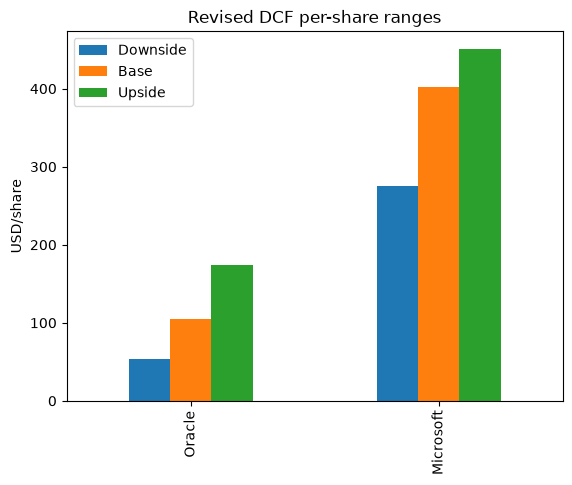

In [17]:
# Comparative exhibit — revised scenario labels
orange=scenarios.set_index('Scenario')['Value / share']; mrange=mscen.set_index('Scenario')['Value/share']
ogap=v['per_share']/MANUAL['price']-1; mgap=mv['per_share']/mprice-1
rec='Neither company is above its revised base DCF at the dated price; Microsoft has the less-negative base gap, while Oracle retains the wider upside range and greater execution risk.'
comp=pd.DataFrame({'Metric':['Downside/base/upside value per share','Dated WRDS price','Base gap $','Base gap %','WACC','Beta','Terminal value/EV','Net debt USD m','Company-specific driver'],
 'Oracle':[f'${orange.Downside:.2f}/${orange.Base:.2f}/${orange.Upside:.2f}',f'${MANUAL["price"]:.2f}',f'${v["per_share"]-MANUAL["price"]:.2f}',f'{ogap:.1%}',f'{v["wacc"]:.2%}',f'{WRDS_BETA:.4f}',f'{v["tv_share"]:.1%}',f'${MANUAL["valuation_net_debt"]:,.0f}','OCI contract conversion and capital efficiency'],
 'Microsoft':[f'${mrange.Downside:.2f}/${mrange.Base:.2f}/${mrange.Upside:.2f}',f'${mprice:.2f}',f'${mv["per_share"]-mprice:.2f}',f'{mgap:.1%}',f'{mv["wacc"]:.2%}',f'{MSFT_BETA:.4f}',f'${mv["tv_share"]:.1%}',f'${mopen["net_debt"]:,.0f} incl. finance leases','Azure/subscriptions/Copilot monetisation and AI capital efficiency']})
display(comp); print('CONDITIONAL RECOMMENDATION:',rec)
compchart=pd.DataFrame({'Downside':[orange.Downside,mrange.Downside],'Base':[orange.Base,mrange.Base],'Upside':[orange.Upside,mrange.Upside]},index=['Oracle','Microsoft']); compchart.plot.bar(title='Revised DCF per-share ranges'); plt.ylabel('USD/share'); plt.show()


# Flip-point analysis — systematic candidate comparison

The comparison tests Oracle operating variables and mechanical valuation variables against Microsoft's revised base relative gap. The preferred final flip point must be an observable operating uncertainty, not merely a discount-rate or terminal-growth adjustment.


In [18]:
target=mv['per_share']/mprice-1
base_orcl=deepcopy(BASE)
def oracle_gap(d,m=MANUAL): return value(company,d,m)['per_share']/m['price']-1
def solve_root(fun, lo, hi, steps=1600):
    xs=np.linspace(lo,hi,steps+1); ys=[fun(x)-target for x in xs]
    roots=[]
    for a,b,fa,fb in zip(xs[:-1],xs[1:],ys[:-1],ys[1:]):
        if fa*fb<=0:
            for _ in range(70):
                mid=(a+b)/2; fm=fun(mid)-target
                if fa*fm<=0: b,fb=mid,fm
                else: a,fa=mid,fm
            roots.append((a+b)/2)
    return roots
base_cagr=np.prod([1+x for x in base_orcl['growth']])**(1/5)-1
cagr_roots=solve_root(lambda k:oracle_gap(dict(base_orcl,growth=[(1+x)**k-1 for x in base_orcl['growth']])),.05,4)
margin_roots=solve_root(lambda x:oracle_gap(dict(base_orcl,margin=base_orcl['margin'][:4]+[x])),.10,.80)
capex_roots=solve_root(lambda x:oracle_gap(dict(base_orcl,capex=[z*x for z in base_orcl['capex']])),.05,1.6)
tg_roots=solve_root(lambda x:oracle_gap(base_orcl,dict(MANUAL,terminal_growth=x)),-.05,.1002)
rfr_roots=solve_root(lambda x:oracle_gap(base_orcl,dict(MANUAL,risk_free_rate=x)),0,.15)
flip_cagr=np.prod([(1+x)**cagr_roots[0] for x in base_orcl['growth']])**.2-1
flip_wacc=value(company,base_orcl,dict(MANUAL,risk_free_rate=rfr_roots[0]))['wacc']
flip_table=pd.DataFrame([
 ['Revenue CAGR',base_cagr,flip_cagr,flip_cagr-base_cagr,'Plausible only if OCI/RPO conversion exceeds the revised base path.','Operating: demand/RPO conversion'],
 ['FY2031 EBIT margin',base_orcl['margin'][4],margin_roots[0],margin_roots[0]-base_orcl['margin'][4],'Plausible only if late-cycle cloud operating leverage exceeds the revised base.','Operating: cloud utilisation and leverage'],
 ['Capex intensity path',1.0,capex_roots[0],capex_roots[0]-1,'Plausible and directly testable if capital productivity improves modestly.','Operating: customer-funded capacity and capital efficiency'],
 ['WACC',v['wacc'],flip_wacc,flip_wacc-v['wacc'],'Not preferred: a market input, not an Oracle execution variable.','Mechanical valuation input'],
 ['Terminal growth',MANUAL['terminal_growth'],tg_roots[0],tg_roots[0]-MANUAL['terminal_growth'],'Secondary only; it relies on distant perpetuity mechanics.','Secondary valuation sensitivity']], columns=['Metric','Revised base assumption','Required flip value','Magnitude of change','Economic plausibility','Interpretation'])
display(flip_table.style.format({'Revised base assumption':'{:.2%}','Required flip value':'{:.2%}','Magnitude of change':'{:+.2%}'}))
print('Recommended primary flip point: Oracle multi-year capex intensity / capital efficiency. FY2031 EBIT margin remains the largest single-year operating sensitivity.')


,Metric,Revised base assumption,Required flip value,Magnitude of change,Economic plausibility,Interpretation
0,Revenue CAGR,20.62%,23.30%,+2.68%,Plausible only if OCI/RPO conversion exceeds the revised base path.,Operating: demand/RPO conversion
1,FY2031 EBIT margin,41.00%,41.77%,+0.77%,Plausible only if late-cycle cloud operating leverage exceeds the revised base.,Operating: cloud utilisation and leverage
2,Capex intensity path,100.00%,96.04%,-3.96%,Plausible and directly testable if capital productivity improves modestly.,Operating: customer-funded capacity and capital efficiency
3,WACC,10.03%,9.90%,-0.12%,"Not preferred: a market input, not an Oracle execution variable.",Mechanical valuation input
4,Terminal growth,3.00%,3.16%,+0.16%,Secondary only; it relies on distant perpetuity mechanics.,Secondary valuation sensitivity


Recommended primary flip point: Oracle multi-year capex intensity / capital efficiency. FY2031 EBIT margin remains the largest single-year operating sensitivity.


# Observable triggers

In [19]:
triggers=pd.DataFrame([
 ['Oracle','FY2027 total revenue','below $90bn','Oracle FY2027 Form 10-K','Below current company guidance and inconsistent with the guidance-led base.'],
 ['Oracle','FY2027 capex and FCF','capex above forecast without improved RPO conversion/customer funding','Oracle FY2027 Form 10-K','Tests the capital-efficiency flip point; Q1 capex was $28.5bn and FCF was negative.'],
 ['Oracle','FY2027 GAAP EBIT margin','below 33%','Oracle FY2027 Form 10-K','Would weaken the revised operating-leverage path.'],
 ['Microsoft','FY2027 Azure growth / total revenue growth','Azure below 40% CC for two quarters or total growth below 16%','Microsoft FY2027 earnings releases','Tests capacity monetisation and the durable-AI base.'],
 ['Microsoft','FY2027 operating margin','declines by more than one point','Microsoft FY2027 Form 10-K',"Tests management's stated margin outlook."],
 ['Microsoft','Finance leases, capex, and Cloud gross margin','investment rises without margin/utilisation recovery','Microsoft FY2027 filings','Tests whether AI investment converts into economic returns.']], columns=['Company','Observable metric','Threshold','Source/review','Explanation'])
display(triggers)


,Company,Observable metric,Threshold,Source/review,Explanation
0,Oracle,FY2027 total revenue,below $90bn,Oracle FY2027 Form 10-K,Below current company guidance and inconsisten...
1,Oracle,FY2027 capex and FCF,capex above forecast without improved RPO conv...,Oracle FY2027 Form 10-K,Tests the capital-efficiency flip point; Q1 ca...
2,Oracle,FY2027 GAAP EBIT margin,below 33%,Oracle FY2027 Form 10-K,Would weaken the revised operating-leverage path.
3,Microsoft,FY2027 Azure growth / total revenue growth,Azure below 40% CC for two quarters or total g...,Microsoft FY2027 earnings releases,Tests capacity monetisation and the durable-AI...
4,Microsoft,FY2027 operating margin,declines by more than one point,Microsoft FY2027 Form 10-K,Tests management's stated margin outlook.
5,Microsoft,"Finance leases, capex, and Cloud gross margin",investment rises without margin/utilisation re...,Microsoft FY2027 filings,Tests whether AI investment converts into econ...


## Priority monitorable triggers

The two priority triggers focus on the operating uncertainties that matter most to the revised DCFs.

| Company | Primary trigger | Why it matters | Other metrics to consider |
|---|---|---|---|
| Oracle | **FY2027 capex and free cash flow:** reassess the thesis if capex exceeds the forecast path without evidence of better RPO conversion, customer funding, or improving cash returns. | Oracle’s key valuation uncertainty is capital efficiency: whether OCI’s exceptional contracted demand converts into revenue and operating profit without requiring persistently higher capital intensity. This is also the recommended flip-point variable. | FY2027 total revenue below **$90bn**; FY2027 GAAP EBIT margin below **33%**; OCI growth, RPO growth and RPO conversion timing. |
| Microsoft | **Azure constant-currency growth and total company revenue growth:** reassess if Azure is below **40% constant currency for two consecutive quarters**, or total revenue growth is below **16%**. | The revised base case depends on sustained Azure consumption, commercial subscriptions, and Copilot/agent monetisation converting AI capacity investment into durable revenue growth. | FY2027 operating margin declines by more than one point; finance-lease obligations and capex rise without utilisation or cloud-margin recovery; Copilot adoption and commercial RPO conversion. |

These triggers are more useful than short-term share-price movements because they test the underlying operating assumptions, rather than the market’s changing valuation multiple.


# Check that changed the model

The initial `trfd` beta attempt was rejected after professional-data validation showed it is an adjustment factor rather than a daily-return series. The method changed to saved Compustat Security Daily `prccd` MSFT/SPY returns and manual covariance/variance beta.

# Revised investment judgment

At the same dated WRDS prices, neither company is above the revised base DCF value. Microsoft now has the smaller base gap and a more diversified recurring base. Oracle retains materially larger upside, but it has much greater dependence on OCI contract conversion and capital efficiency. Microsoft’s AI data-center and finance-lease obligations still restrain near-term FCFF.

**Conditional conclusion:** Microsoft is the stronger relative base-case choice in the final model; Oracle remains the higher-upside, higher-risk alternative. Neither is a standalone buy at the dated WRDS price under the final base case.


In [20]:
# Revised assumptions ledger and companion outputs
outdir = ROOT / 'capstone'
orange=scenarios.set_index('Scenario')['Value / share']; mrange=mscen.set_index('Scenario')['Value/share']
ogap=v['per_share']/MANUAL['price']-1; mgap=mv['per_share']/mprice-1
comp=pd.DataFrame({'Metric':['Downside/base/upside value per share','Dated WRDS price','Base gap $','Base gap %','WACC','Beta','Terminal value / EV','Net debt USD m','Company-specific driver'],
 'Oracle':[f'${orange.Downside:.2f}/${orange.Base:.2f}/${orange.Upside:.2f}',f'${MANUAL["price"]:.2f}',f'${v["per_share"]-MANUAL["price"]:.2f}',f'{ogap:.1%}',f'{v["wacc"]:.2%}',f'{WRDS_BETA:.4f}',f'{v["tv_share"]:.1%}',f'${MANUAL["valuation_net_debt"]:,.0f}','OCI contract conversion and capital efficiency'],
 'Microsoft':[f'${mrange.Downside:.2f}/${mrange.Base:.2f}/${mrange.Upside:.2f}',f'${mprice:.2f}',f'${mv["per_share"]-mprice:.2f}',f'{mgap:.1%}',f'{mv["wacc"]:.2%}',f'{MSFT_BETA:.4f}',f'{mv["tv_share"]:.1%}',f'${mopen["net_debt"]:,.0f} incl. finance leases','Azure/subscriptions/Copilot monetisation and AI capital efficiency']})
display(comp); comp.to_csv(outdir/'capstone_exhibit.csv',index=False)
ledger = f"""# Assumptions ledger — revised audited run

## Oracle

- Capital structure: Q1 FY2027 net debt ${MANUAL['valuation_net_debt']:,.0f}m at {MANUAL['valuation_balance_date']}; shares 3,023.736m at 2026-09-07.
- Base growth: 35%, 28%, 20%, 14%, 8%; margins: 35%, 37%, 39%, 40%, 41%; capex/revenue: 70%, 55%, 42%, 32%, 25%.
- Evidence: [Oracle Q1 FY2027 earnings release](https://investor.oracle.com/investor-news/news-details/2026/Oracle-Announces-Q1-Results-Driven-by-Triple-Digit-Growth-in-Cloud-Infrastructure-Revenues/default.aspx) and [SEC Q1 FY2027 8-K exhibit](https://www.sec.gov/Archives/edgar/data/1341439/000119312526387905/orcl-ex99_1.htm): +30% revenue, +62% cloud, +121% OCI, $664bn RPO, at least $90bn FY2027 revenue guide, and $28.5bn Q1 capex.

## Microsoft

- Finance-lease liabilities: ${M_FINANCE_LEASE:,.0f}m are included in debt, WACC and net debt; the corresponding finance-lease PP&E is already included in reported PP&E.
- Base growth: 19%, 20%, 19%, 17%, 14%; margins: 46.0%, 46.5%, 47.5%, 48.5%, 49.5%; capex/revenue: 45%, 38%, 30%, 23%, 17%.
- Evidence: [Microsoft FY2026 10-K](https://www.sec.gov/Archives/edgar/data/789019/000119312526323660/msft-20260630.htm) and [FY2026 Q4 earnings/guidance](https://www.microsoft.com/en-us/investor/events/fy-2026/earnings-fy-2026-q4): $214.4bn Microsoft Cloud, $678bn commercial RPO, about 30% expected in 12 months, 45% Azure Q1 CC guide, and continuing AI capex.

All forecast arrays are model judgments, not management guidance. Dated WRDS prices are comparison points only.
"""
# The detailed assumptions ledger is maintained as a reviewed companion Markdown file.
print('REVISED COMPANION OUTPUTS WRITTEN')


,Metric,Oracle,Microsoft
0,Downside/base/upside value per share,$53.78/$104.59/$173.89,$274.77/$401.59/$451.07
1,Dated WRDS price,$137.79,$512.90
2,Base gap $,$-33.20,$-111.31
3,Base gap %,-24.1%,-21.7%
4,WACC,10.03%,8.87%
5,Beta,1.6369,0.9360
6,Terminal value / EV,101.5%,89.4%
7,Net debt USD m,"$88,968","$85,953 incl. finance leases"
8,Company-specific driver,OCI contract conversion and capital efficiency,Azure/subscriptions/Copilot monetisation and A...


REVISED COMPANION OUTPUTS WRITTEN


# Defence facts

In [21]:
print('REVISED RUN SUMMARY')
print('Oracle range',comp.loc[0,'Oracle'],'price',MANUAL['price'],'base gap',f'{ogap:.1%}','WACC',f'{v["wacc"]:.2%}')
print('Microsoft range',comp.loc[0,'Microsoft'],'price',mprice,'base gap',f'{mgap:.1%}','WACC',f'{mv["wacc"]:.2%}')
display(flip_table); display(triggers)
print('Checks: SEC known-answer gates, WRDS prccd betas, linked forecast ties, Oracle Q1 capital bridge, and Microsoft finance-lease treatment.')


REVISED RUN SUMMARY
Oracle range $53.78/$104.59/$173.89 price 137.79 base gap -24.1% WACC 10.03%
Microsoft range $274.77/$401.59/$451.07 price 512.9 base gap -21.7% WACC 8.87%


,Metric,Revised base assumption,Required flip value,Magnitude of change,Economic plausibility,Interpretation
0,Revenue CAGR,0.21,0.23,0.03,Plausible only if OCI/RPO conversion exceeds t...,Operating: demand/RPO conversion
1,FY2031 EBIT margin,0.41,0.42,0.01,Plausible only if late-cycle cloud operating l...,Operating: cloud utilisation and leverage
2,Capex intensity path,1.00,0.96,-0.04,Plausible and directly testable if capital pro...,Operating: customer-funded capacity and capita...
3,WACC,0.10,0.10,-0.00,"Not preferred: a market input, not an Oracle e...",Mechanical valuation input
4,Terminal growth,0.03,0.03,0.00,Secondary only; it relies on distant perpetuit...,Secondary valuation sensitivity


,Company,Observable metric,Threshold,Source/review,Explanation
0,Oracle,FY2027 total revenue,below $90bn,Oracle FY2027 Form 10-K,Below current company guidance and inconsisten...
1,Oracle,FY2027 capex and FCF,capex above forecast without improved RPO conv...,Oracle FY2027 Form 10-K,Tests the capital-efficiency flip point; Q1 ca...
2,Oracle,FY2027 GAAP EBIT margin,below 33%,Oracle FY2027 Form 10-K,Would weaken the revised operating-leverage path.
3,Microsoft,FY2027 Azure growth / total revenue growth,Azure below 40% CC for two quarters or total g...,Microsoft FY2027 earnings releases,Tests capacity monetisation and the durable-AI...
4,Microsoft,FY2027 operating margin,declines by more than one point,Microsoft FY2027 Form 10-K,Tests management's stated margin outlook.
5,Microsoft,"Finance leases, capex, and Cloud gross margin",investment rises without margin/utilisation re...,Microsoft FY2027 filings,Tests whether AI investment converts into econ...


Checks: SEC known-answer gates, WRDS prccd betas, linked forecast ties, Oracle Q1 capital bridge, and Microsoft finance-lease treatment.


# AI disclosure — revised

ChatGPT and Codex assisted with source organization, notebook structure, code implementation, audit checks, and evidence-led sensitivity design. SEC filings, company earnings materials, and saved authenticated WRDS `prccd` returns were independently checked in the notebook. The final betas use covariance divided by SPY variance from matched `prccd` returns. The revised model judgments distinguish company guidance from lower-confidence FY2028–31 scenario assumptions; dated market prices are comparison points, not inputs used to select operating assumptions.
